# ***1.Data Collection***

In [307]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [308]:
#importing dataset from kagglehub
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

# Reading each table separately
customers   = pd.read_csv(f"{path}/olist_customers_dataset.csv")
geolocation = pd.read_csv(f"{path}/olist_geolocation_dataset.csv")
order_items = pd.read_csv(f"{path}/olist_order_items_dataset.csv")
payments    = pd.read_csv(f"{path}/olist_order_payments_dataset.csv")
reviews     = pd.read_csv(f"{path}/olist_order_reviews_dataset.csv")
orders      = pd.read_csv(f"{path}/olist_orders_dataset.csv")
products    = pd.read_csv(f"{path}/olist_products_dataset.csv")
sellers     = pd.read_csv(f"{path}/olist_sellers_dataset.csv")
category_translation = pd.read_csv(f"{path}/product_category_name_translation.csv")




Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.


In [309]:
# Creating dictionary containing all tables
data = {'customers': customers,
'geolocation' : geolocation,
'order_items': order_items,
'payments': payments,
'reviews': reviews,
'orders': orders,
'products': products,
'sellers': sellers,
'category_translation': category_translation}


# ***2.Data Inspection***

In [310]:
# Identifying the shape of each table
for key, value in data.items():
    print(f'{key}: {value.shape}')

customers: (99441, 5)
geolocation: (1000163, 5)
order_items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)
orders: (99441, 8)
products: (32951, 9)
sellers: (3095, 4)
category_translation: (71, 2)


In [311]:
# Displaying the head of each table
for key, value in data.items():
  print(f'\n{key}:')
  display(value.head())


customers:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



geolocation:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



order_items:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (8 outputs left out)


sellers:


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP



category_translation:


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [312]:
# Identifying the data info of each table
for key, value in data.items():
  print(f'\n{key}:')
  value.info()


customers:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

geolocation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city     

In [313]:
# Identifying statistical information of each table
for key, value in data.items():
  print(f'\n{key}:')
  display(value.describe(include='all').T)


customers:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,99441,99441,06b8999e2fba1a1fbc88172c00ba8bc7,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,99441,96096,8d50f5eadf50201ccdcedfb9e2ac8455,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,99441.0,NaN,NaN,NaN,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0
customer_city,99441,4119,sao paulo,15540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,99441,27,SP,41746,NaN,NaN,NaN,NaN,NaN,NaN,NaN



geolocation:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,NaN,NaN,NaN,36574.166466,30549.33571,1001.0,11075.0,26530.0,63504.0,99990.0
geolocation_lat,1000163.0,NaN,NaN,NaN,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.97962,45.065933
geolocation_lng,1000163.0,NaN,NaN,NaN,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394
geolocation_city,1000163,8011,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_state,1000163,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN



order_items:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,112650,98666,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,112650.0,NaN,NaN,NaN,1.197834,0.705124,1.0,1.0,1.0,1.0,21.0
product_id,112650,32951,aca2eb7d00ea1a7b8ebd4e68314663af,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,112650,3095,6560211a19b47992c3666cc44a7e94c0,2033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_limit_date,112650,93318,2017-07-21 18:25:23,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,112650.0,NaN,NaN,NaN,120.653739,183.633928,0.85,39.9,74.99,134.9,6735.0
freight_value,112650.0,NaN,NaN,NaN,19.99032,15.806405,0.0,13.08,16.26,21.15,409.68


... (8 outputs left out)


sellers:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
seller_id,3095,3095,3442f8959a84dea7ee197c632cb2df15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_zip_code_prefix,3095.0,NaN,NaN,NaN,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0
seller_city,3095,611,sao paulo,694,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_state,3095,23,SP,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN



category_translation:


,count,unique,top,freq
product_category_name,71,71,beleza_saude,1
product_category_name_english,71,71,health_beauty,1


# ***3.Data Cleaning***

# *3.1.Data Type Conversion*

In [314]:
# Converting Date columns
date_cols=['review_creation_date','review_answer_timestamp','shipping_limit_date','order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date']
for key, value in data.items():
    for i in date_cols:
        if i in value.columns:
            value[i] = pd.to_datetime(value[i], errors='coerce')

In [315]:
# Rechecking columns data types
for key, value in data.items():
  print(f'\n{key}:')
  value.info()


customers:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

geolocation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city     

# *3.2.Duplicated Rows*

In [316]:
# Identifying duplicated rows
for key, value in data.items():
     print(key,"Duplicate Rows:",value.duplicated().sum())

# Insight: Geolocation is the only table containing duplicated values

customers Duplicate Rows: 0
geolocation Duplicate Rows: 261831
order_items Duplicate Rows: 0
payments Duplicate Rows: 0
reviews Duplicate Rows: 0
orders Duplicate Rows: 0
products Duplicate Rows: 0
sellers Duplicate Rows: 0
category_translation Duplicate Rows: 0


In [317]:
# Dropping duplicated rows in geolocation table
geolocation.drop_duplicates(inplace=True)


# *3.3.Missing Values*

In [318]:
for key, value in data.items():
    print(f'\n{key}:')
    print(value.isnull().sum())


customers:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

geolocation:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

order_items:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

payments:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

reviews:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

orders:
order_id      

# *3.3.1.Handling Missing Values in Reviews Table*

In [319]:
# Dropping from reviews table the two columns for reviews comments with many missing values

reviews.drop(columns=['review_comment_title', 'review_comment_message'],inplace=True)

# *3.3.2.Handling Missing Values in Orders Table*

### Know whether missing dates are connected to particular order statuses.

In [320]:
#counting the number of null orders of approval dates in orders status for each category
orders[orders['order_approved_at'].isnull()]['order_status'].value_counts()

,count
order_status,
canceled,141
delivered,14
created,5


In [321]:
#counting the number of null orders of carrier dates in orders status for each category
orders[orders['order_delivered_carrier_date'].isnull()]['order_status'].value_counts()

,count
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,2


In [322]:
#counting the number of null orders of delivery dates in orders status for each category
orders[orders['order_delivered_customer_date'].isnull()]['order_status'].value_counts()

,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


In [323]:
#checking for orders that were delivered to the customer but have no approval date
orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_approved_at'].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22
48401,7002a78c79c519ac54022d4f8a65e6e8,d5de688c321096d15508faae67a27051,delivered,2017-01-19 22:26:59,NaT,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16
61743,2eecb0d85f281280f79fa00f9cec1a95,a3d3c38e58b9d2dfb9207cab690b6310,delivered,2017-02-17 17:21:55,NaT,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20


In [324]:
#orders that were delivered to the customer but have no delivery carrier date
orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_carrier_date'].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
73222,2aa91108853cecb43c84a5dc5b277475,afeb16c7f46396c0ed54acb45ccaaa40,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaT,2017-11-20 19:44:47,2017-11-14
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23


In [325]:
#checking for orders that marked as delivered to the customer but have no delivery date
orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


*Insight: Missing date values were left as NaT rather than imputed, as they are not expected to have a significant impact on the model.*










# *3.4.Data Validation*

# *3.4.1.Data Validation for "Orders" Table*

In [326]:
#checking for orders that were approved before being purchased
orders[(orders['order_approved_at'] <
     orders['order_purchase_timestamp'])]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


In [327]:
#checking for orders that were delivered to the carrier before placement of the order
orders[(orders['order_delivered_carrier_date'] <
     orders['order_purchase_timestamp'])]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
615,b9afddbdcfadc9a87b41a83271c3e888,85c6af75161b8b2b1af98e82b5a6a5a5,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,2018-08-24 14:58:37,2018-09-04
1111,ad133696906f6a78826daa0911b7daec,e6f5b234bb0d847f10eebd70130c5d49,delivered,2018-06-15 15:41:22,2018-06-15 16:19:23,2018-06-15 14:52:00,2018-06-22 18:09:37,2018-07-18
1329,74e033208dc13a7b8127eb8e73d09b76,72fcbb1145f2889eddcba6d6c1d6c090,delivered,2018-05-02 10:48:44,2018-05-02 11:13:45,2018-05-02 09:49:00,2018-05-07 23:06:36,2018-05-29
1372,a6b58794fd2ba533359a76c08df576e3,ccd8e3459ad58ae538c9d2cf35532ba4,delivered,2018-05-14 15:18:23,2018-05-14 15:33:35,2018-05-14 13:46:00,2018-05-19 19:33:32,2018-06-08
1864,5792e0b1c8c8a2bf53af468c9a422c88,5c427f06e7fcf902e309743516e2c580,delivered,2018-07-26 13:25:14,2018-07-26 13:35:14,2018-07-26 12:42:00,2018-07-30 14:45:02,2018-08-09
...,...,...,...,...,...,...,...,...
98172,f7780ea2807db31691e83f0013294035,3088cc4bfafe311f1d84830808c2aa6d,delivered,2018-07-30 15:22:15,2018-07-30 15:35:16,2018-07-30 15:00:00,2018-08-02 18:32:30,2018-08-02
98430,d7646ffe8fdd9e7d9557f9f7cbf04530,f896e70d84f6db9a56b86a47dd8718f0,delivered,2018-05-04 14:50:37,2018-05-04 15:10:22,2018-05-04 14:48:00,2018-05-08 19:06:42,2018-05-16
98672,5ded8a3706eabd813685534724f066de,460316e38d4d241fc79d4f6729f8f7f6,delivered,2018-07-18 08:46:52,2018-07-18 09:01:48,2018-07-18 08:44:00,2018-07-25 13:53:17,2018-08-10
98780,d10046876c7d9f01613da59ffa6cb07f,6559cb5b365f173915f766fefcd86972,delivered,2018-07-18 16:14:16,2018-07-18 16:25:17,2018-07-18 15:34:00,2018-07-23 20:46:44,2018-08-07


In [328]:
#creating table for orders that were delivered to the carrier before placement of the order
invalid_carrier_dates = (
    orders['order_delivered_carrier_date'] <
    orders['order_purchase_timestamp']
)

invalid_carrier_dates.sum()

np.int64(166)

In [329]:
#checking for orders that were delivered to the customer before being delivered to the carrier
orders[orders['order_delivered_customer_date'] <orders['order_delivered_carrier_date']]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,5f50465da00b7fed5dd1239f4ecf6e2c,delivered,2017-07-20 11:20:52,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56,2017-08-14
9553,383aa8b2724fe452d9ccd9934a8c628b,b1cb2f9d7a19480f3749e248db14d58f,delivered,2017-07-02 20:58:43,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51,2017-07-21
13487,cb1134f9010d242e9515ad1c78ec0c39,2fd33ac77677bd214b1882868317eeed,delivered,2017-07-16 12:35:34,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28,2017-08-08
14474,dceb62e8fa94b46006c9554fed743df0,2721900eb4e0f1cc2c836dd7bc1b1e11,delivered,2017-07-20 20:58:05,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10,2017-08-11
19268,5f9d46795c3126674e52becb3a1a517f,79287bcaafdde5c793b996fc40bb7d9f,delivered,2017-07-18 11:48:20,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41,2017-07-31
21338,8c78d01de3a9009e23d6877a7cc9be20,6cd7106899e59a1fbd0622d5f1efedf4,delivered,2016-10-08 15:36:50,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46,2016-11-30
22520,b27af682321527a6349f1761eb3f360c,9859dd92e872dbaa60ca3cd5f0d7ad07,delivered,2017-06-14 20:17:04,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35,2017-07-14
25393,1cc3ae63caffff2d6c3ee3e78e074acf,01c843a2c0600def0b7693dba47af460,delivered,2017-08-07 21:35:22,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38,2017-08-25
25646,e37f11cae9985ca58f0b56f268720537,3947a361301f2ff0f3223159a0f2701c,delivered,2017-07-26 11:46:34,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56,2017-08-24
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,63be4feff10a0b1d85f2cfbf10df9754,delivered,2017-07-30 19:32:23,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01,2017-08-18


In [330]:
#checking for orders that were delivered to the customer before placement of the order
orders[
    (orders['order_delivered_customer_date'] <
     orders['order_purchase_timestamp'])
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


In [331]:
# Converting unlogical delivered_carrier_date to NaT
invalid_carrier = (orders['order_delivered_carrier_date'] <
    orders['order_purchase_timestamp'])

invalid_customer_delivery = (orders['order_delivered_customer_date'] <
    orders['order_delivered_carrier_date'])

orders.loc[invalid_carrier, 'order_delivered_carrier_date'] = pd.NaT

orders.loc[invalid_customer_delivery, 'order_delivered_carrier_date'] = pd.NaT

*Insight: Chronologically inconsistent delivery dates were identified and converted to NaT. Carrier delivery dates earlier than the purchase timestamp were treated as invalid. For orders whose customer delivery date was earlier than the carrier delivery date, the carrier date was converted to NaT, and the customer delivery date was kept because it is the key field for delivery-time features. The affected orders were kept rather than deleted.*










In [332]:
print(orders['customer_id'].isin(customers['customer_id']).sum())
print("Total orders:", len(orders))

99441
Total orders: 99441


In [333]:
print(orders['order_id'].isin(order_items['order_id']).sum())
print("Total orders:", len(orders))

98666
Total orders: 99441


In [334]:
orders_without_items = orders[
    ~orders['order_id'].isin(order_items['order_id'])
]

orders_without_items['order_status'].value_counts()

,count
order_status,
unavailable,603
canceled,164
created,5
invoiced,2
shipped,1


*Insight: 775 orders have no associated order_items.
These records are retained in the orders dataset and will be excluded from purchase-related analysis.*










In [335]:
print(orders['order_id'].isin(payments['order_id']).sum())
print("Total orders:", len(orders))

99440
Total orders: 99441


In [336]:
orders_without_payments = orders[
    ~orders['order_id'].isin(payments['order_id'])
]

orders_without_payments[
    ['order_id', 'order_status', 'order_purchase_timestamp']
]

,order_id,order_status,order_purchase_timestamp
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,2016-09-15 12:16:38


*Insight: One delivered order has no associated payment record. It is retained in the orders dataset and will be excluded from purchase-related analysis.*

# *3.4.2.Data Validation for "Products" Table*

In [337]:
products[
    products['product_category_name'].isna()
][
    ['product_category_name',
     'product_name_lenght',
     'product_description_lenght',
     'product_photos_qty']
].isna().all(axis=1).value_counts()

,count
True,610


In [338]:
products[
    products[['product_weight_g',
              'product_length_cm',
              'product_height_cm',
              'product_width_cm']].isna().any(axis=1)
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [339]:
products['product_id'].duplicated().sum()

np.int64(0)

In [340]:
dimensions = [
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

(products[dimensions] <= 0).sum()

,0
product_weight_g,4
product_length_cm,0
product_height_cm,0
product_width_cm,0


In [341]:
products[products['product_weight_g'] <= 0]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


In [342]:
products['product_weight_g'] = products['product_weight_g'].replace(0, np.nan)

In [343]:
products['product_weight_g'].isna().sum()

np.int64(6)

In [344]:
(products['product_weight_g'] <= 0).sum()

np.int64(0)

# *3.4.3.Data Validation for "Orders Items" Table*

In [345]:
order_items.duplicated(subset=['order_id', 'order_item_id']).sum()

np.int64(0)

In [346]:
order_items[['price', 'freight_value']].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [347]:
(order_items[['price', 'freight_value']] < 0).sum()

,0
price,0
freight_value,0


In [348]:
order_items.nlargest(10, 'price')[
    ['order_id', 'product_id', 'price', 'freight_value']
]

,order_id,product_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,3999.90,17.01


In [349]:
order_items.nlargest(10, 'freight_value')[['order_id', 'product_id', 'price', 'freight_value']]

,order_id,product_id,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,ec31d2a17b299511e7c8627be9337b9b,979.00,409.68
3303,076d1555fb53a89b0ef4d529e527a0f6,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
28044,3fde74c28a3d5d618c00f26d51baafa0,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
69797,9f49bd16053df810384e793386312674,256a9c364b75753b97bee410c9491ad8,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,46e24ce614899e36617e37ea1e4aa6ff,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,363a9f5b97bf194da23858be722a7aa5,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,7e53e051875b2a0c9f22acd8a9a29a20,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,363a9f5b97bf194da23858be722a7aa5,1045.00,314.40


In [351]:
order_items.groupby('order_id')['order_item_id'].nunique().describe()

,order_item_id
count,98666.000000
mean,1.141731
std,0.538452
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,21.000000


In [352]:
print(order_items['product_id'].isin(products['product_id']).sum())
print("Total order items:", len(order_items))

112650
Total order items: 112650


In [353]:
print(order_items['seller_id'].isin(sellers['seller_id']).sum())
print("Total order items:", len(order_items))

112650
Total order items: 112650


# *3.4.4.Data Validation for "Payments" Table*

In [354]:
payments['payment_type'].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [355]:
payments[payments['payment_type'] == 'not_defined']

,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


In [356]:
undefined_orders = payments[
    payments['payment_type'] == 'not_defined'
]['order_id']

orders[orders['order_id'].isin(undefined_orders)][
    ['order_id', 'order_status']
]

,order_id,order_status
1130,00b1cb0320190ca0daa2c88b35206009,canceled
39919,4637ca194b6387e2d538dc89b124b0ee,canceled
40235,c8c528189310eaa44a745b8d9d26908b,canceled


In [357]:
payments[['payment_value', 'payment_installments']].describe()

,payment_value,payment_installments
count,103886.000000,103886.000000
mean,154.100380,2.853349
std,217.494064,2.687051
min,0.000000,0.000000
25%,56.790000,1.000000
50%,100.000000,1.000000
75%,171.837500,4.000000
max,13664.080000,24.000000


In [358]:
(payments[['payment_value', 'payment_installments']] <= 0).sum()

,0
payment_value,9
payment_installments,2


In [359]:
payments[
    (payments['payment_value'] <= 0) |
    (payments['payment_installments'] <= 0)
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.00
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.00
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.00
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00


In [360]:
affected_orders = payments[
    (payments['payment_value'] <= 0) |
    (payments['payment_installments'] <= 0)
]['order_id'].unique()

orders[orders['order_id'].isin(affected_orders)][
    ['order_id', 'order_status']
]

,order_id,order_status
423,45ed6e85398a87c253db47c2d9f48216,delivered
1130,00b1cb0320190ca0daa2c88b35206009,canceled
25932,fa65dad1b0e818e3ccc5cb0e39231352,shipped
32287,6ccb433e00daae1283ccc956189c82ae,delivered
39919,4637ca194b6387e2d538dc89b124b0ee,canceled
40235,c8c528189310eaa44a745b8d9d26908b,canceled
63782,744bade1fcf9ff3f31d860ace076d422,delivered
66368,1a57108394169c0b47d8f876acc9ba2d,delivered
85786,b23878b3e8eb4d25a158f57d96331b18,delivered
96970,8bcbe01d44d147f901cd3192671144db,delivered


In [361]:
payments[payments['order_id'].isin(affected_orders)].sort_values(
    ['order_id', 'payment_sequential']
)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
33781,45ed6e85398a87c253db47c2d9f48216,1,voucher,1,21.13
11755,45ed6e85398a87c253db47c2d9f48216,2,voucher,1,50.01
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
40546,6ccb433e00daae1283ccc956189c82ae,1,credit_card,5,84.67
93478,6ccb433e00daae1283ccc956189c82ae,2,voucher,1,14.65
92318,6ccb433e00daae1283ccc956189c82ae,3,voucher,1,22.72
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00


In [362]:
payments[
    payments['order_id'].isin(
        payments.loc[
            payments['payment_installments'] == 0,
            'order_id'
        ]
    )
].sort_values(['order_id', 'payment_sequential'])

,order_id,payment_sequential,payment_type,payment_installments,payment_value
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69


# *3.4.5.Data Validation for "Reviews" Table*

In [363]:
reviews['review_score'].value_counts(dropna=False).sort_index()

,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [364]:
reviews['review_id'].duplicated().sum()

np.int64(814)

In [365]:
reviews[reviews['review_id'].duplicated(keep=False)].sort_values('review_id')

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,2018-03-07,2018-03-08 03:00:53
...,...,...,...,...,...
31120,fe5c833752953fed3209646f1f63b53c,4863e15fa53273cc7219c58f5ffda4fb,1,2018-02-28,2018-02-28 13:57:52
7870,ff2fc9e68f8aabfbe18d710b83aabd30,2da58e0a7dcfa4ce1e00fad9d03ca3b5,2,2018-03-17,2018-03-19 11:44:15
82521,ff2fc9e68f8aabfbe18d710b83aabd30,1078d496cc6ab9a8e6f2be77abf5091b,2,2018-03-17,2018-03-19 11:44:15
73951,ffb8cff872a625632ac983eb1f88843c,c44883fc2529b4aa03ca90e7e09d95b6,3,2017-07-22,2017-07-26 13:41:07


In [366]:
print(reviews['order_id'].isin(orders['order_id']).sum())
print("Total reviews:", len(reviews))

99224
Total reviews: 99224


# *3.4.6.Data Validation for "Customers" Table*

In [367]:
customers['customer_unique_id'].duplicated().sum()

np.int64(3345)

In [368]:
print("Duplicate customer_id:", customers['customer_id'].duplicated().sum())
print("Duplicate customer_unique_id:", customers['customer_unique_id'].duplicated().sum())

Duplicate customer_id: 0
Duplicate customer_unique_id: 3345


*Insight: customer_id is generated for each order, while customer_unique_id identifies the actual customer. customer_unique_id will be used for all customer-level analysis and repeat-purchase prediction.*

# *3.4.7.Data Validation for "Sellers" Table*

In [369]:
print("Duplicate seller_id:", sellers['seller_id'].duplicated().sum())
print("Invalid ZIP prefixes:", (sellers['seller_zip_code_prefix'] <= 0).sum())

Duplicate seller_id: 0
Invalid ZIP prefixes: 0


# *3.4.8.Data Validation for "Geolocation" Table*

In [370]:
print("Exact duplicate rows:", geolocation.duplicated().sum())

print(
    "Invalid coordinates:",
    (
        ~geolocation['geolocation_lat'].between(-90, 90)
        | ~geolocation['geolocation_lng'].between(-180, 180)
    ).sum()
)

Exact duplicate rows: 0
Invalid coordinates: 0


# *3.4.9.Data Validation for "Category Translation" Table*

In [371]:
print("Exact duplicate rows:", category_translation.duplicated().sum())

print(
    "Duplicate category names:",
    category_translation['product_category_name'].duplicated().sum()
)

Exact duplicate rows: 0
Duplicate category names: 0


# *3.5.Handling Outliers*

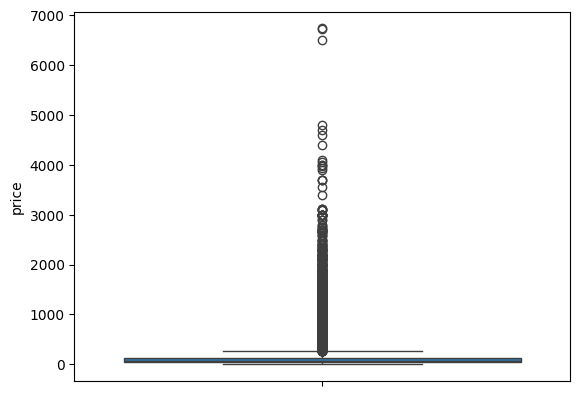

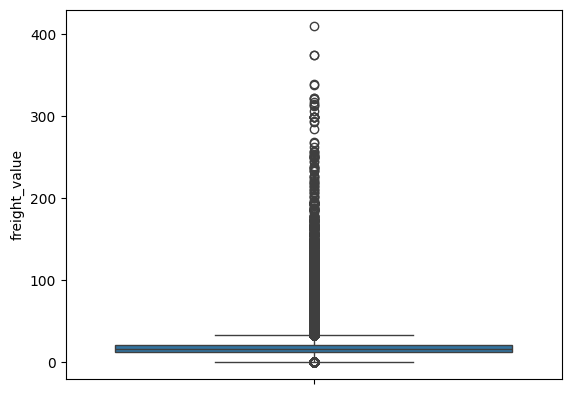

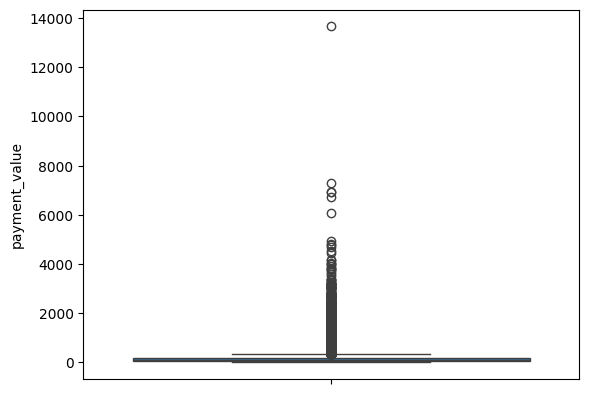

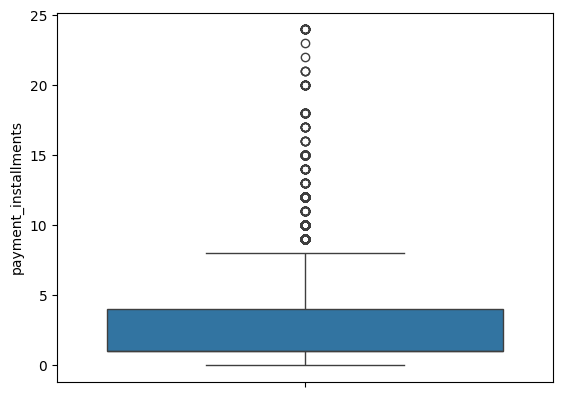

In [373]:
# Identifying the columns to be checked for outliers and creating boxplot for each

columns_to_check = ['price', 'freight_value', 'payment_value', 'payment_installments']
for key, value in data.items():
  for i in columns_to_check:
    if i in value.columns:
      sns.boxplot(value[i])
      plt.show()

In [386]:
# Calculating IQR and the percentage of outliers in the selected columns
for key, df in data.items():
    for col in columns_to_check:
        if col in df.columns:
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1

            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR

            outliers = df[col][(df[col] < lower) | (df[col] > upper)]
            print(f'{col}: {len(outliers)} ({outliers.shape[0] / df[col].notna().sum() * 100:.2f}%)')

price: 8427 (7.48%)
freight_value: 12134 (10.77%)
payment_value: 7981 (7.68%)
payment_installments: 6313 (6.08%)


In [383]:
# Investigating zero values for the selected columns
for key, df in data.items():
    for col in columns_to_check:
        if col in df.columns:
            print(col, (df[col] == 0).sum())

price 0
freight_value 383
payment_value 9
payment_installments 2


In [387]:
# Coverting zero values in "payment installments" column into Nan
payments['payment_installments'] = payments['payment_installments'].replace(0, np.nan)

In [385]:
# Rechecking zero values for the selected columns
for key, df in data.items():
    for col in columns_to_check:
        if col in df.columns:
            print(col, (df[col] == 0).sum())

price 0
freight_value 383
payment_value 9
payment_installments 0


*Insight: Outliers in price, freight_value, payment_value and payment_installments were kept, because they represent real transactions (expensive products, high shipping costs, large orders). Zero freight values reflect free shipping and zero payment values reflect vouchers, so they were also kept. Only zero installments were treated as invalid and converted to NaN.*

# ***4.Exporting Cleaned Data***

In [372]:
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

processed_data = {
    "olist_customers_dataset.csv": customers,
    "olist_geolocation_dataset.csv": geolocation,
    "olist_order_items_dataset.csv": order_items,
    "olist_order_payments_dataset.csv": payments,
    "olist_order_reviews_dataset.csv": reviews,
    "olist_orders_dataset.csv": orders,
    "olist_products_dataset.csv": products,
    "olist_sellers_dataset.csv": sellers,
    "product_category_name_translation.csv": category_translation
}

for filename, df in processed_data.items():
    df.to_csv(processed_dir / filename, index=False)
    print(f"{filename}: {len(df):,} rows saved")

olist_customers_dataset.csv: 99,441 rows saved
olist_geolocation_dataset.csv: 738,332 rows saved
olist_order_items_dataset.csv: 112,650 rows saved
olist_order_payments_dataset.csv: 103,886 rows saved
olist_order_reviews_dataset.csv: 99,224 rows saved
olist_orders_dataset.csv: 99,441 rows saved
olist_products_dataset.csv: 32,951 rows saved
olist_sellers_dataset.csv: 3,095 rows saved
product_category_name_translation.csv: 71 rows saved
